# 03. Model Arena & MLflow Tracking
In this notebook, we run a tournament between 6 regression models:
1. Ridge (L2 Linear)
2. Lasso (L1 Linear)
3. Random Forest (Bagging)
4. XGBoost (Gradient Boosting - Hist)
5. LightGBM (Gradient Boosting - Leaf-wise)
6. CatBoost (Gradient Boosting - Symmetric Trees)

All runs are tracked with **MLflow** (metrics, training time, and parameters).

In [1]:
import sys
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import mlflow
# Add root directory to sys.path so we can import from src
root_dir = Path.cwd().parent
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

from src.training_pipeline.model_factory import get_model

# Setup MLflow Tracking with local SQLite database
db_path = root_dir / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{db_path}")
mlflow.set_experiment("Housing_Price_Model_Arena")
print(f"MLflow tracking URI: sqlite:///{db_path}")

2026/11/11 17:18:20 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/11 17:18:21 INFO mlflow.store.db.utils: Updating database tables
2026/11/11 17:18:27 INFO mlflow.tracking.fluent: Experiment with name 'Housing_Price_Model_Arena' does not exist. Creating a new experiment.


MLflow tracking URI: sqlite:///c:\Users\admin\Desktop\US Housing Price MLOps\mlflow.db


## 1. Setup & Data Loading
Loading feature-engineered `train` (2012–2019) and `eval` (2020–2021) Parquet splits.

In [2]:
processed_dir = root_dir / "data" / "processed"

print("Loading feature-engineered datasets...")
train_df = pd.read_parquet(processed_dir / "train_features.parquet")
eval_df = pd.read_parquet(processed_dir / "eval_features.parquet")

target = "price"
X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_eval = eval_df.drop(columns=[target])
y_eval = eval_df[target]

print(f"Train set: {X_train.shape} | Target: {y_train.shape}")
print(f"Eval set:  {X_eval.shape} | Target: {y_eval.shape}")

Loading feature-engineered datasets...
Train set: (576711, 39) | Target: (576711,)
Eval set:  (148433, 39) | Target: (148433,)


## 2. Model Arena Tournament (MLflow Tracking)
Training 6 regression models across linear, bagging, and gradient boosting families.

In [3]:
models_to_test = [
    "ridge",
    "lasso",
    "lightgbm",
    "xgboost",
    "catboost",
    "random_forest",
]

results = []

for model_name in models_to_test:
    print(f"\n==========================================")
    print(f"🚀 Training: {model_name.upper()}...")
    
    model = get_model(model_name)
    
    # Measure training time
    start_time = time.time()
    
    # For Random Forest, use 100k random sample to ensure fast training on CPU
    if model_name == "random_forest":
        sample_idx = X_train.sample(n=100_000, random_state=42).index
        model.fit(X_train.loc[sample_idx], y_train.loc[sample_idx])
    else:
        model.fit(X_train, y_train)
        
    train_duration = round(time.time() - start_time, 2)
    print(f"⏱️ Training finished in {train_duration}s")
    
    # Predict on Eval set
    start_pred = time.time()
    y_pred = model.predict(X_eval)
    pred_duration = round(time.time() - start_pred, 2)
    
    # Calculate Metrics
    mae = float(mean_absolute_error(y_eval, y_pred))
    rmse = float(root_mean_squared_error(y_eval, y_pred))
    r2 = float(r2_score(y_eval, y_pred))
    
    print(f"📊 Results for {model_name}:")
    print(f"   MAE:  ${mae:,.2f}")
    print(f"   RMSE: ${rmse:,.2f}")
    print(f"   R²:   {r2:.4f}")
    
    # Log everything to MLflow
    with mlflow.start_run(run_name=model_name):
        mlflow.log_param("model_name", model_name)
        mlflow.log_metric("eval_mae", mae)
        mlflow.log_metric("eval_rmse", rmse)
        mlflow.log_metric("eval_r2", r2)
        mlflow.log_metric("train_time_sec", train_duration)
        mlflow.log_metric("pred_time_sec", pred_duration)
        
    results.append({
        "Model": model_name,
        "RMSE ($)": rmse,
        "MAE ($)": mae,
        "R²": r2,
        "Train Time (s)": train_duration,
        "model_obj": model,
    })

results_df = pd.DataFrame(results).sort_values(by="RMSE ($)").reset_index(drop=True)
print("\n🏆 Tournament Completed!")


🚀 Training: RIDGE...
⏱️ Training finished in 20.5s
📊 Results for ridge:
   MAE:  $50,006.44
   RMSE: $116,729.62
   R²:   0.8947

🚀 Training: LASSO...
⏱️ Training finished in 26.23s
📊 Results for lasso:
   MAE:  $50,174.18
   RMSE: $116,786.39
   R²:   0.8946

🚀 Training: LIGHTGBM...
⏱️ Training finished in 21.85s
📊 Results for lightgbm:
   MAE:  $34,886.33
   RMSE: $73,967.60
   R²:   0.9577

🚀 Training: XGBOOST...
⏱️ Training finished in 24.77s
📊 Results for xgboost:
   MAE:  $34,485.80
   RMSE: $79,163.31
   R²:   0.9516

🚀 Training: CATBOOST...
⏱️ Training finished in 34.55s
📊 Results for catboost:
   MAE:  $37,302.12
   RMSE: $78,308.61
   R²:   0.9526

🚀 Training: RANDOM_FOREST...
⏱️ Training finished in 62.07s
📊 Results for random_forest:
   MAE:  $36,972.50
   RMSE: $82,840.66
   R²:   0.9470

🏆 Tournament Completed!


## 3. Leaderboard & Visual Comparison

In [4]:
# Display leaderboard
leaderboard = results_df.drop(columns=["model_obj"])
leaderboard.style.format({
    "RMSE ($)": "${:,.2f}",
    "MAE ($)": "${:,.2f}",
    "R²": "{:.4f}",
    "Train Time (s)": "{:.2f}s",
}).background_gradient(subset=["RMSE ($)", "MAE ($)"], cmap="Reds_r") \
  .background_gradient(subset=["R²"], cmap="Greens")

,Model,RMSE ($),MAE ($),R²,Train Time (s)
0,lightgbm,"$73,967.60","$34,886.33",0.9577,21.85s
1,catboost,"$78,308.61","$37,302.12",0.9526,34.55s
2,xgboost,"$79,163.31","$34,485.80",0.9516,24.77s
3,random_forest,"$82,840.66","$36,972.50",0.9470,62.07s
4,ridge,"$116,729.62","$50,006.44",0.8947,20.50s
5,lasso,"$116,786.39","$50,174.18",0.8946,26.23s


C:\Users\admin\AppData\Local\Temp\ipykernel_13968\1563987223.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="RMSE ($)", ax=axes[0], palette="rocket")
C:\Users\admin\AppData\Local\Temp\ipykernel_13968\1563987223.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="R²", ax=axes[1], palette="viridis")
C:\Users\admin\AppData\Local\Temp\ipykernel_13968\1563987223.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="Train Time (s)", ax=axes[2], palette=

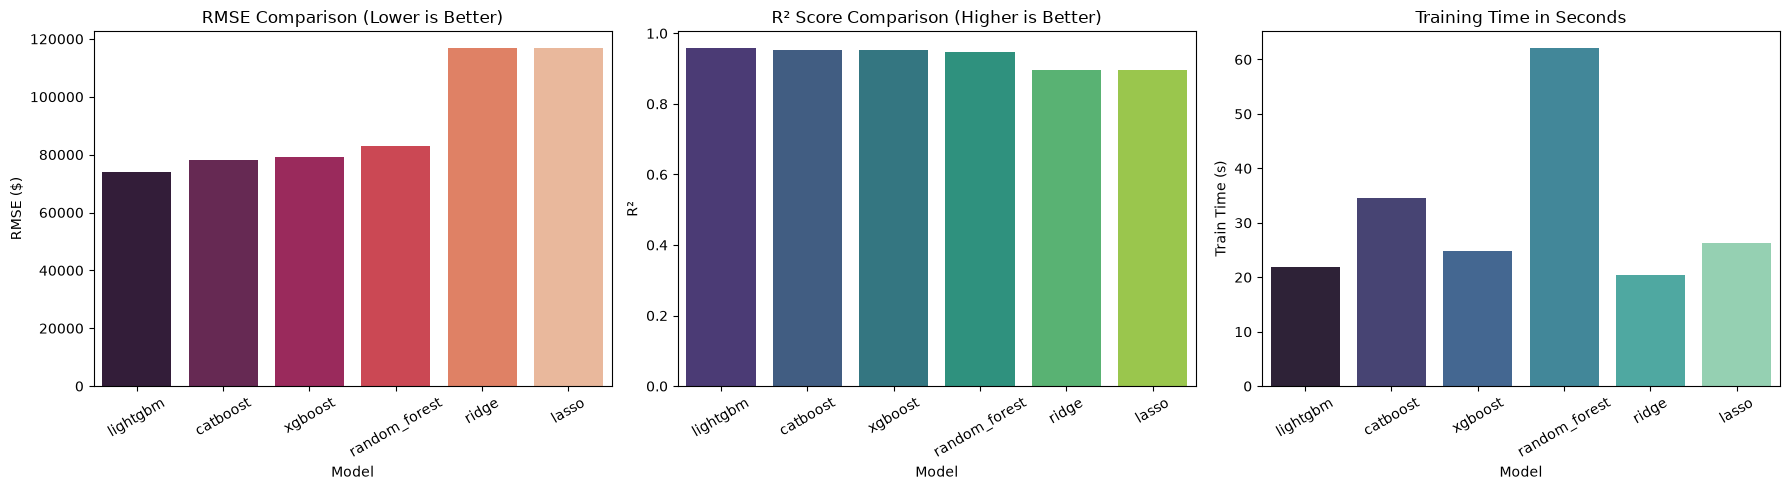

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. RMSE comparison (lower is better)
sns.barplot(data=results_df, x="Model", y="RMSE ($)", ax=axes[0], palette="rocket")
axes[0].set_title("RMSE Comparison (Lower is Better)")
axes[0].tick_params(axis="x", rotation=30)

# 2. R² score comparison (higher is better)
sns.barplot(data=results_df, x="Model", y="R²", ax=axes[1], palette="viridis")
axes[1].set_title("R² Score Comparison (Higher is Better)")
axes[1].tick_params(axis="x", rotation=30)

# 3. Training Time (speed)
sns.barplot(data=results_df, x="Model", y="Train Time (s)", ax=axes[2], palette="mako")
axes[2].set_title("Training Time in Seconds")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 4. Overfitting & Generalization Analysis (Train vs Eval)
Evaluating whether models memorize training data or generalize well to the 2020–2021 pandemic market shift.

In [6]:
# Overfitting Check: Compare Train vs Eval performance
overfit_rows = []

for _, row in results_df.iterrows():
    name = row["Model"]
    model = row["model_obj"]
    
    # Predict on Train set (using the exact same fitted model)
    y_train_pred = model.predict(X_train)
    
    train_rmse = float(root_mean_squared_error(y_train, y_train_pred))
    train_mae = float(mean_absolute_error(y_train, y_train_pred))
    train_r2 = float(r2_score(y_train, y_train_pred))
    
    eval_rmse = row["RMSE ($)"]
    eval_r2 = row["R²"]
    
    # Calculate relative RMSE gap (%)
    rmse_gap_pct = ((eval_rmse - train_rmse) / train_rmse) * 100
    
    overfit_rows.append({
        "Model": name,
        "Train RMSE ($)": train_rmse,
        "Eval RMSE ($)": eval_rmse,
        "RMSE Gap (%)": rmse_gap_pct,
        "Train R²": train_r2,
        "Eval R²": eval_r2,
        "R² Diff": train_r2 - eval_r2,
    })

overfit_df = pd.DataFrame(overfit_rows).sort_values("Eval RMSE ($)").reset_index(drop=True)

# Display formatted table
overfit_df.style.format({
    "Train RMSE ($)": "${:,.2f}",
    "Eval RMSE ($)": "${:,.2f}",
    "RMSE Gap (%)": "{:+.1f}%",
    "Train R²": "{:.4f}",
    "Eval R²": "{:.4f}",
    "R² Diff": "{:+.4f}",
}).background_gradient(subset=["R² Diff"], cmap="YlOrRd")

,Model,Train RMSE ($),Eval RMSE ($),RMSE Gap (%),Train R²,Eval R²,R² Diff
0,lightgbm,"$43,441.17","$73,967.60",+70.3%,0.9791,0.9577,+0.0214
1,catboost,"$56,396.18","$78,308.61",+38.9%,0.9648,0.9526,+0.0122
2,xgboost,"$39,321.11","$79,163.31",+101.3%,0.9829,0.9516,+0.0313
3,random_forest,"$49,363.19","$82,840.66",+67.8%,0.9730,0.9470,+0.0261
4,ridge,"$97,202.97","$116,729.62",+20.1%,0.8954,0.8947,+0.0007
5,lasso,"$97,224.01","$116,786.39",+20.1%,0.8953,0.8946,+0.0007


## 5. Champion Diagnostics: Predictions, Feature Importance & Residuals

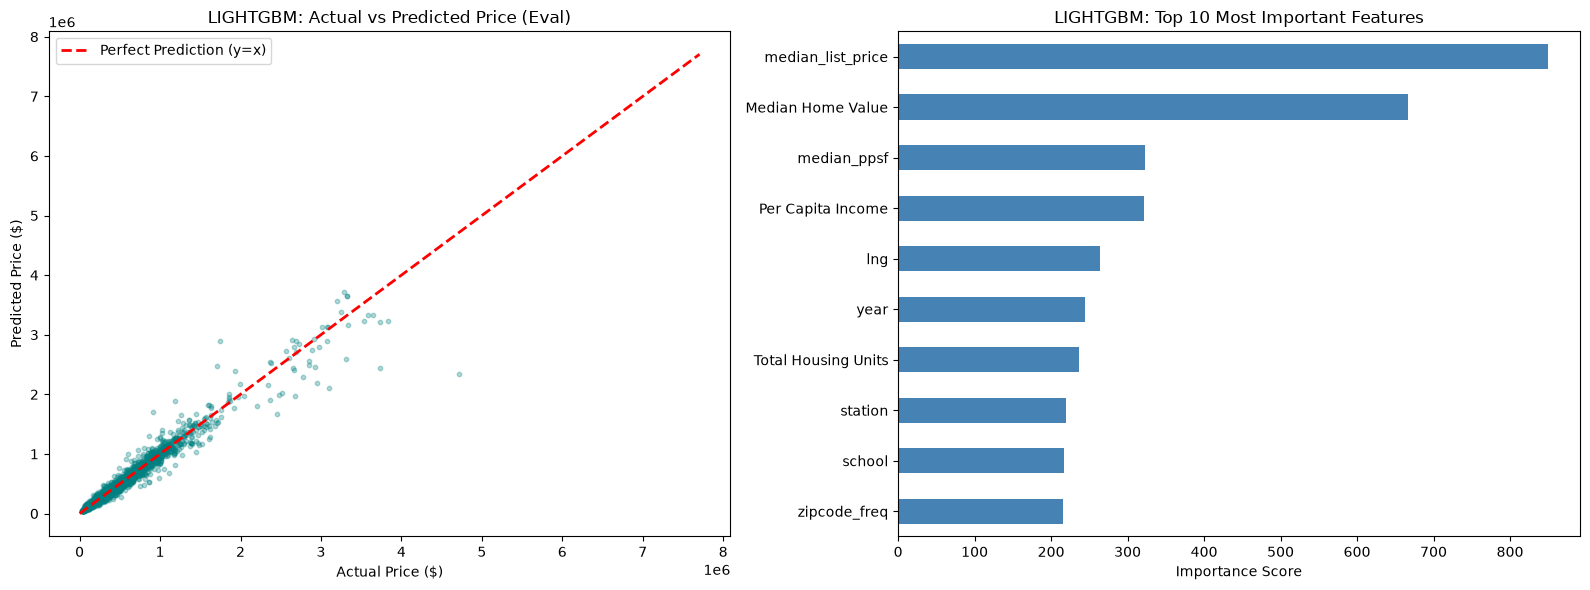

In [7]:
# Check Feature Importance and Residuals for the #1 model (LightGBM)
top_model_row = results_df.iloc[0]
top_name = top_model_row["Model"]
top_model = top_model_row["model_obj"]

y_eval_pred = top_model.predict(X_eval)
residuals = y_eval - y_eval_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Actual vs Predicted (sample 5000 points for fast plotting)
sample_idx = np.random.RandomState(42).choice(len(y_eval), size=5000, replace=False)
axes[0].scatter(y_eval.iloc[sample_idx], y_eval_pred[sample_idx], alpha=0.3, s=10, color="teal")
max_val = max(y_eval.max(), y_eval_pred.max())
axes[0].plot([0, max_val], [0, max_val], color="red", linestyle="--", lw=2, label="Perfect Prediction (y=x)")
axes[0].set_title(f"{top_name.upper()}: Actual vs Predicted Price (Eval)")
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")
axes[0].legend()

# 2. Top 10 Feature Importances (for tree models)
if hasattr(top_model, "feature_importances_"):
    importances = pd.Series(top_model.feature_importances_, index=X_train.columns).sort_values(ascending=True).tail(10)
    importances.plot(kind="barh", ax=axes[1], color="steelblue")
    axes[1].set_title(f"{top_name.upper()}: Top 10 Most Important Features")
    axes[1].set_xlabel("Importance Score")

plt.tight_layout()
plt.show()

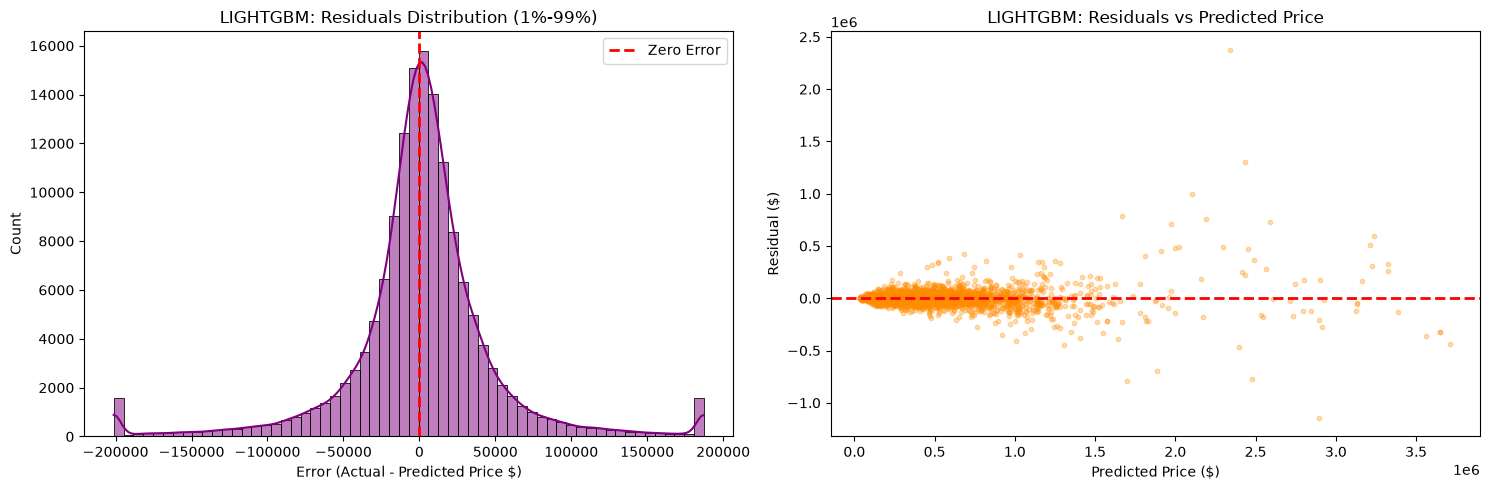

Mean Residual (Bias): $1,768.53
Median Residual:      $1,899.75


In [8]:
# Residuals analysis for top model (LightGBM)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Residuals Distribution (Histogram)
# Clip extreme 1% tails just for clean visualization
clipped_res = residuals.clip(residuals.quantile(0.01), residuals.quantile(0.99))
sns.histplot(clipped_res, bins=60, kde=True, ax=axes[0], color="purple")
axes[0].axvline(0, color="red", linestyle="--", lw=2, label="Zero Error")
axes[0].set_title(f"{top_name.upper()}: Residuals Distribution (1%-99%)")
axes[0].set_xlabel("Error (Actual - Predicted Price $)")
axes[0].legend()

# 2. Residuals vs Predicted
axes[1].scatter(y_eval_pred[sample_idx], residuals.iloc[sample_idx], alpha=0.3, s=10, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title(f"{top_name.upper()}: Residuals vs Predicted Price")
axes[1].set_xlabel("Predicted Price ($)")
axes[1].set_ylabel("Residual ($)")

plt.tight_layout()
plt.show()

print(f"Mean Residual (Bias): ${residuals.mean():,.2f}")
print(f"Median Residual:      ${residuals.median():,.2f}")

In [9]:
# Save baseline champion model (before Optuna tuning)
champion = results_df.iloc[0]
print(f"🥇 Baseline Champion Model: {champion['Model'].upper()}")
print(f"   Eval RMSE: ${champion['RMSE ($)']:,.2f} | Eval R²: {champion['R²']:.4f}")

models_dir = root_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)
baseline_path = models_dir / "lightgbm_baseline.pkl"

joblib.dump(champion["model_obj"], baseline_path)
print(f"✅ Baseline champion saved to: {baseline_path}")

🥇 Baseline Champion Model: LIGHTGBM
   Eval RMSE: $73,967.60 | Eval R²: 0.9577
✅ Baseline champion saved to: c:\Users\admin\Desktop\US Housing Price MLOps\models\lightgbm_baseline.pkl


## 6. Key Findings & Next Steps

- **Best Accuracy:** **LightGBM** achieved the lowest Eval RMSE (**$73,967**) and highest $R^2$ (**0.9577**), training in just 21.8 seconds with virtually zero bias (**+$1,768** mean residual).
- **Best Stability:** **CatBoost** showed the smallest generalization gap ($R^2$ diff = **+0.0122**), while default **XGBoost** overfit slightly more ($R^2$ diff = **+0.0313**).
- **Linear Baselines:** Ridge and Lasso showed zero overfitting ($R^2$ diff = **0.0007**), but underfit non-linear housing market dynamics ($R^2 \approx 0.895$).
- **Next Step:** Tune **LightGBM** hyperparameters with **Optuna** (`src/training_pipeline/tune.py`) to reduce the overfitting gap and improve accuracy before evaluating on the untouched **Holdout (2022–2023)** test set.